# Case Study 17 — The Missing Income Problem

**Missing data mechanisms (MCAR / MAR / MNAR) · missingness analysis · complete-case analysis · mean, group-mean,
regression and stochastic imputation · missing-indicator method · multiple imputation with Rubin's rules · why the
outcome belongs in the imputation model · delta-adjusted sensitivity analysis for MNAR · inference vs prediction**

| | |
|---|---|
| **Domain** | Retail lending: personal-loan scorecard |
| **Stakeholders** | Head of Credit Risk, Scorecard Model Owner |
| **Difficulty** | Intermediate |
| **Importance** | 🟠 SHOULD GO THROUGH |
| **Builds on** | Case 11 (logistic regression), Case 07–08 (multiple regression, bias) |
| **Data** | 8,000 personal-loan applications with a known 12-month default outcome |

> **This dataset is synthetic** and was generated to reproduce a realistic business scenario. It is not actual
> customer data. See `src/generate_data.py`. A separate **answer key** (the true income of every applicant) exists only
> because the data are simulated; the notebook opens it **only in Section 11**, to grade the strategies. In real life
> the true values of missing data are never known; that is the whole difficulty.

**What you will learn**

1. The three missing-data mechanisms, how to **investigate** missingness, and what you can and cannot learn from the
   data about it.
2. What each common fix (delete, mean-fill, regression-fill, indicator, multiple imputation) does to **averages**,
   **spread** and **regression coefficients**.
3. Why **multiple imputation** gives honest uncertainty, and why the **outcome must be in the imputation model**.
4. How to test how wrong you could be if the missingness is **not at random** (sensitivity analysis).
5. Why the best strategy for **explaining** (inference) differs from the best for **scoring new applicants**
   (prediction).

## Section 1 — Business context

You are a data scientist in **Credit Risk**. The personal-loan scorecard uses **monthly income**, but about a quarter
of applications arrive without it (customers skip the field, agents do not upload payslips, or income is "pending
verification"). The model owner proposes two quick fixes:

> *"(a) Delete the applications with missing income from the model data: we still have thousands left. (b) For
> scoring, fill the missing income with the average income so the model can run. Isn't that enough?"*

The Head of Credit Risk is worried: *"The people who skip the income field are not a random sample. Will the model
understate how much income protects against default? Will it misprice the applicants who don't provide income?"*

## Section 2 — Business questions

1. How much data is missing, and where?
2. Why is it missing? Is it random?
3. What does each fix do to the average income, the spread of income and the estimated effect of income on default?
4. Which strategy should we use to **estimate** the income effect, and which to **score** applicants without income?
5. How much could our conclusions change if missingness is related to income itself?

## Section 3 — Statistical translation

| # | Business question | Statistical question | Method |
|---|---|---|---|
| 1 | How much, where? | Missingness rates, patterns by variable | Missingness table and pattern counts |
| 2 | Why? | Does missingness depend on observed variables (MAR), on the missing value itself (MNAR), or on nothing (MCAR)? | Comparison of observed variables by missingness status; logistic regression of the missing indicator |
| 3 | Effect of each fix | Bias and variance of estimates under complete-case analysis and several imputation methods | Mean, SD of log income; logistic coefficient of income |
| 4 | Estimation vs scoring | Valid inference vs predictive accuracy for new applicants | Multiple imputation + Rubin's rules; out-of-sample AUC / Brier |
| 5 | Sensitivity | How do conclusions move if missing incomes are systematically lower than imputed? | Delta-adjusted multiple imputation |

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.linear_model import BayesianRidge, LogisticRegression
from sklearn.metrics import roc_auc_score, brier_score_loss, log_loss
from sklearn.model_selection import train_test_split

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "00_shared_resources").is_dir())
sys.path.insert(0, str(ROOT / "00_shared_resources"))
from utils import case_paths, save_table, fmt_money, fmt_p, rng_for_case
from plotting import set_style, save_fig, add_note, COLORS, CATEGORICAL, PRIMARY, HIGHLIGHT, INK, INK_MUTED

CASE_DIR = ROOT / "case_studies" / "17_missing_income"
PATHS = case_paths(CASE_DIR)
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
rng = rng_for_case(1717)
pctfmt = plt.FuncFormatter(lambda v, _: f"{v:.0%}")
LI0 = 10.7          # centring constant: log(₹44,700)

## Section 4 — Load the data

In [2]:
apps = pd.read_csv(PATHS["data"] / "applications.csv")
print(f"{apps.shape[0]:,} applications × {apps.shape[1]} columns;  duplicate ids: {apps['app_id'].duplicated().sum()}")
display(apps.head())
apps["employment_type"] = pd.Categorical(apps["employment_type"], categories=["Salaried", "Self-employed", "Gig"])
apps["channel"] = pd.Categorical(apps["channel"], categories=["Branch", "Online", "Agent"])
apps["income_missing"] = apps["monthly_income"].isna().astype(int)
apps["score_missing"] = apps["credit_score"].isna().astype(int)
apps["years_missing"] = apps["employment_years"].isna().astype(int)
apps["li"] = np.log(apps["monthly_income"]) - LI0                      # centred log income (NaN when missing)
apps["score_c"] = (apps["credit_score"].fillna(650) - 700) / 10      # missing score = thin file, set to 650 (see Section 5)
apps["log_loan"] = np.log(apps["loan_amount"])

8,000 applications × 10 columns;  duplicate ids: 0


,app_id,age,employment_type,channel,city_tier,loan_amount,employment_years,monthly_income,credit_score,defaulted
0,AP17100000,51,Salaried,Online,2,"276,000.0000",17.5000,NaN,686.0000,0
1,AP17100001,34,Self-employed,Online,3,"216,000.0000",0.5000,"28,600.0000",743.0000,0
2,AP17100002,46,Self-employed,Branch,1,"417,000.0000",19.8000,"61,300.0000",697.0000,0
3,AP17100003,41,Gig,Agent,3,"326,000.0000",3.7000,"23,000.0000",679.0000,1
4,AP17100004,26,Salaried,Agent,1,"113,000.0000",1.0000,"48,900.0000",701.0000,0


## Section 5 — How much is missing, and where?

,missing,share missing
employment_years,383,0.0479
monthly_income,1876,0.2345
credit_score,495,0.0619


,income missing,score missing (thin file),years missing,applications,share
0,0,0,0,5507,0.6884
1,1,0,0,1640,0.2050
2,0,1,0,325,0.0406
3,0,0,1,277,0.0346
4,1,1,0,145,0.0181
5,1,0,1,81,0.0101
6,0,1,1,15,0.0019
7,1,1,1,10,0.0013


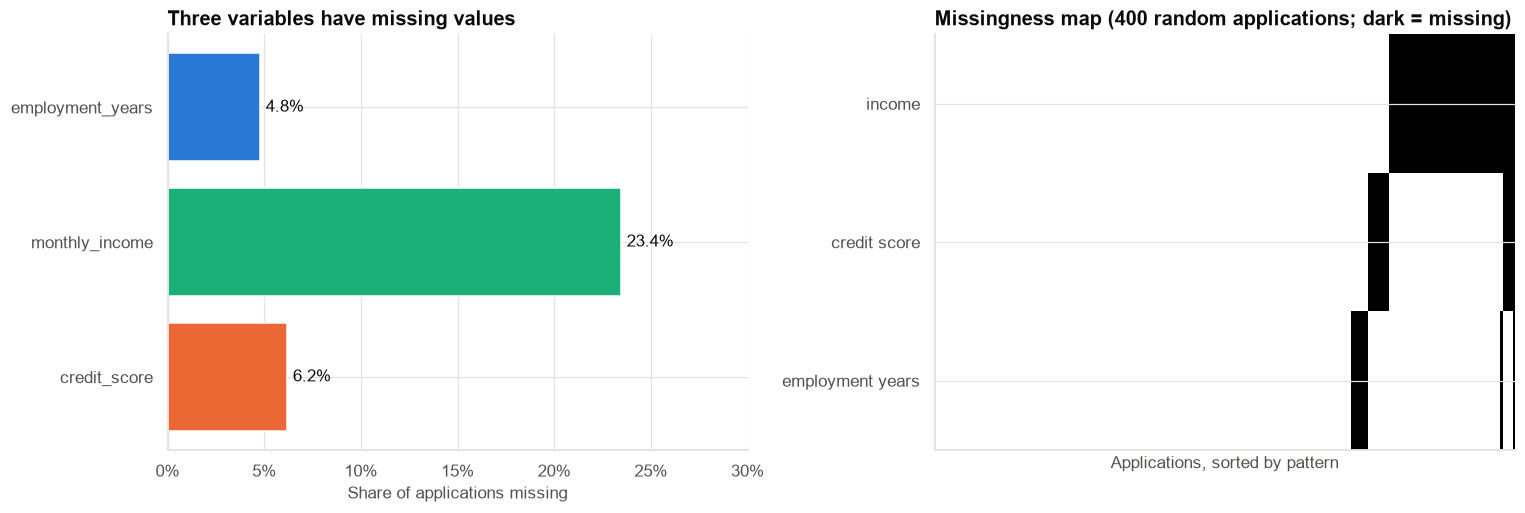

In [3]:
miss = apps[["age", "employment_type", "channel", "city_tier", "loan_amount", "employment_years", "monthly_income", "credit_score", "defaulted"]].isna()
miss_tbl = pd.DataFrame({"missing": miss.sum(), "share missing": miss.mean()}).query("missing > 0")
save_table(miss_tbl, "missingness_by_variable", PATHS["tables"])
display(miss_tbl)
patterns = (apps[["income_missing", "score_missing", "years_missing"]]
            .value_counts().rename("applications").reset_index()
            .rename(columns={"income_missing": "income missing", "score_missing": "score missing (thin file)", "years_missing": "years missing"}))
patterns["share"] = patterns["applications"] / len(apps)
save_table(patterns.set_index(["income missing", "score missing (thin file)", "years missing"]), "missingness_patterns", PATHS["tables"])
display(patterns)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.barh(miss_tbl.index[::-1], miss_tbl["share missing"][::-1], color=[PRIMARY, COLORS["aqua"], HIGHLIGHT][::-1][: len(miss_tbl)])
for i, v in enumerate(miss_tbl["share missing"][::-1]):
    ax.text(v + 0.003, i, f"{v:.1%}", va="center")
ax.xaxis.set_major_formatter(pctfmt)
ax.set(title="Three variables have missing values", xlabel="Share of applications missing", xlim=(0, 0.3))
ax = axes[1]
sample = apps.sample(400, random_state=1).sort_values(["income_missing", "score_missing", "years_missing"])
mat = sample[["monthly_income", "credit_score", "employment_years"]].isna().to_numpy().T.astype(int)
ax.imshow(mat, aspect="auto", cmap="Greys", interpolation="nearest")
ax.set_yticks(range(3), ["income", "credit score", "employment years"])
ax.set_xticks([])
ax.set(title="Missingness map (400 random applications; dark = missing)", xlabel="Applications, sorted by pattern")
fig.tight_layout()
save_fig(fig, "fig01_missingness_overview", PATHS["figures"])
plt.show()

**Observation.** **Income** is missing for 23% of applications, **credit score** for 6%, and **employment years**
for 5%. The patterns are mostly independent: most applications miss at most one variable.

**What "missing" means for each variable:**
- **Income:** the customer or the agent did not supply it.
- **Credit score:** the customer has **no credit history** (a "thin file"). The value is not lost; it does not
  exist. Its absence is itself information (thin-file customers are riskier), so we model it with a **thin-file flag**
  and set the score to a neutral 650 when it is absent.
- **Employment years:** a data-entry gap.

## Section 6 — Why is income missing? Investigating the mechanism

| Mechanism | Definition | Example here | Consequence |
|---|---|---|---|
| **MCAR** (completely at random) | Missingness is unrelated to anything | A form field lost in a system glitch | Complete-case analysis is unbiased (but loses data) |
| **MAR** (at random, given what we observe) | Missingness depends only on **observed** variables | Agents upload payslips less often for gig workers | Complete-case can be biased; **multiple imputation** using the observed variables is valid |
| **MNAR** (not at random) | Missingness depends on the **missing value itself** (even given observed variables) | Low earners avoid giving proof of income | **No standard method fixes this without assumptions**; do a sensitivity analysis |

**What the data can show:** whether missingness is related to **observed** variables (so it is *not* MCAR).
**What it cannot show:** whether it is also related to the missing value itself (MNAR). That needs assumptions or
outside knowledge.

In [4]:
def smd(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

cmp_rows = []
for col, lab in [("age", "age"), ("loan_amount", "loan amount (₹)"), ("city_tier", "city tier"), ("credit_score", "credit score (where present)"),
                 ("defaulted", "default rate")]:
    a, b = apps.loc[apps.income_missing == 1, col].dropna(), apps.loc[apps.income_missing == 0, col].dropna()
    cmp_rows.append({"variable": lab, "income missing": a.mean(), "income present": b.mean(), "standardised difference": smd(a, b),
                     "p_value": stats.ttest_ind(a, b, equal_var=False).pvalue})
for col in ["employment_type", "channel"]:
    for lvl in apps[col].cat.categories:
        a = (apps.loc[apps.income_missing == 1, col] == lvl); b = (apps.loc[apps.income_missing == 0, col] == lvl)
        cmp_rows.append({"variable": f"{col} = {lvl} (share)", "income missing": a.mean(), "income present": b.mean(),
                         "standardised difference": smd(a.astype(float), b.astype(float)),
                         "p_value": stats.chi2_contingency(pd.crosstab(apps[col] == lvl, apps.income_missing))[1]})
cmp_tbl = pd.DataFrame(cmp_rows).set_index("variable")
save_table(cmp_tbl, "missing_vs_present", PATHS["tables"])
display(cmp_tbl)

m_miss = smf.logit("income_missing ~ C(employment_type) + C(channel) + age + city_tier + log_loan + score_c + score_missing + defaulted", apps).fit(disp=0)
m_null = smf.logit("income_missing ~ 1", apps).fit(disp=0)
lr_stat = 2 * (m_miss.llf - m_null.llf)
print(f"Does anything observed predict whether income is missing?  LR χ² = {lr_stat:.0f} on {int(m_miss.df_model)} df, p = {fmt_p(stats.chi2.sf(lr_stat, m_miss.df_model))}")
print(f"AUC of that model: {roc_auc_score(apps.income_missing, m_miss.predict()):.3f}  (0.5 = missingness unrelated to observed variables)")
orm = pd.DataFrame({"odds ratio": np.exp(m_miss.params), "ci_low": np.exp(m_miss.conf_int()[0]), "ci_high": np.exp(m_miss.conf_int()[1]),
                    "p_value": m_miss.pvalues}).drop("Intercept")
save_table(orm, "missingness_model_odds_ratios", PATHS["tables"])
orm

,income missing,income present,standardised difference,p_value
variable,,,,
age,34.0410,35.6269,-0.1874,0.0000
loan amount (₹),"249,899.7868","328,628.8374",-0.4018,0.0000
city tier,2.0325,1.8449,0.2455,0.0000
credit score (where present),678.6717,693.3734,-0.2470,0.0000
default rate,0.3145,0.1494,0.3987,0.0000
employment_type = Salaried (share),0.4232,0.6466,-0.4595,0.0000
employment_type = Self-employed (share),0.3150,0.2322,0.1866,0.0000
employment_type = Gig (share),0.2617,0.1212,0.3630,0.0000
channel = Branch (share),0.2527,0.3810,-0.2784,0.0000


Does anything observed predict whether income is missing?  LR χ² = 890 on 10 df, p = < 0.001


AUC of that model: 0.718  (0.5 = missingness unrelated to observed variables)


,odds ratio,ci_low,ci_high,p_value
C(employment_type)[T.Self-employed],2.3547,2.0711,2.6773,0.0000
C(employment_type)[T.Gig],2.7864,2.4076,3.2249,0.0000
C(channel)[T.Online],1.7941,1.5703,2.0498,0.0000
C(channel)[T.Agent],2.0685,1.7870,2.3944,0.0000
age,0.9844,0.9779,0.9910,0.0000
city_tier,1.2499,1.1614,1.3453,0.0000
log_loan,0.5824,0.5287,0.6415,0.0000
score_c,0.9901,0.9801,1.0002,0.0540
score_missing,1.1185,0.9009,1.3886,0.3102
defaulted,2.1180,1.8542,2.4192,0.0000


,LR χ²,df,p_value,AUC
employment years missing,16.2654,8.0000,0.0387,0.5567
credit score missing (thin file),192.9903,8.0000,0.0000,0.6812


Default rate: income present 14.9%, income missing 31.4%;  thin file 37.6% vs score present 17.6%


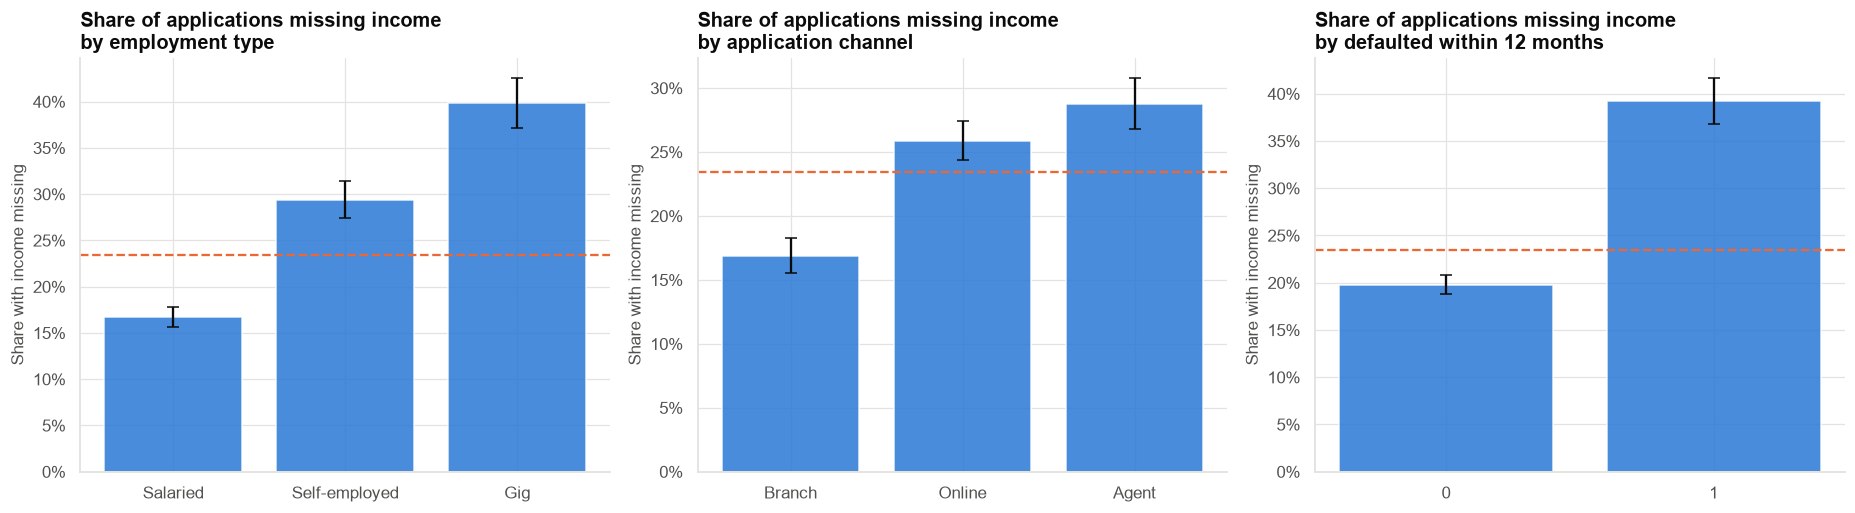

In [5]:
mcar = {}
for col in ["years_missing", "score_missing"]:
    m1 = smf.logit(f"{col} ~ C(employment_type) + C(channel) + age + city_tier + log_loan + defaulted", apps).fit(disp=0)
    lr_ = 2 * (m1.llf - smf.logit(f"{col} ~ 1", apps).fit(disp=0).llf)
    mcar[col] = {"LR χ²": lr_, "df": int(m1.df_model), "p_value": stats.chi2.sf(lr_, m1.df_model), "AUC": roc_auc_score(apps[col], m1.predict())}
mcar = pd.DataFrame(mcar).T
mcar.index = ["employment years missing", "credit score missing (thin file)"]
save_table(mcar, "other_missingness_tests", PATHS["tables"])
display(mcar)
print(f"Default rate: income present {apps.loc[apps.income_missing == 0, 'defaulted'].mean():.1%}, income missing {apps.loc[apps.income_missing == 1, 'defaulted'].mean():.1%};  "
      f"thin file {apps.loc[apps.score_missing == 1, 'defaulted'].mean():.1%} vs score present {apps.loc[apps.score_missing == 0, 'defaulted'].mean():.1%}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (col, lab) in zip(axes, [("employment_type", "Employment type"), ("channel", "Application channel"), ("defaulted", "Defaulted within 12 months")]):
    g = apps.groupby(col, observed=True)["income_missing"].agg(["mean", "sum", "size"])
    ci = np.array([stats.beta.interval(0.95, k + 0.5, n - k + 0.5) for k, n in zip(g["sum"], g["size"])])
    ax.bar([str(i) for i in g.index], g["mean"], color=PRIMARY, alpha=0.85)
    ax.errorbar(range(len(g)), g["mean"], yerr=[g["mean"] - ci[:, 0], ci[:, 1] - g["mean"]], fmt="none", color=INK, capsize=4)
    ax.axhline(apps["income_missing"].mean(), color=HIGHLIGHT, ls="--", lw=1.5)
    ax.yaxis.set_major_formatter(pctfmt)
    ax.set(title=f"Share of applications missing income\nby {lab.lower()}", ylabel="Share with income missing")
fig.tight_layout()
save_fig(fig, "fig02_missingness_drivers", PATHS["figures"])
plt.show()

**Observation.**
- Income is **far from MCAR**: employment type, application channel and, strikingly, the **default outcome** all predict
  whether income is missing (the missingness model's likelihood-ratio test is overwhelming; its AUC is well above
  0.5). Gig workers, self-employed applicants and agent/online applicants omit income more often. Applicants who
  **later default** omit income about twice as often.
- **Smaller loans, higher city tiers and younger applicants** are also more likely to lack income.
- **Employment years** shows at most a weak relationship with the other variables (p = 0.04, AUC 0.56: borderline,
  and not surprising when two such tests are run), consistent with a random data-entry gap (MCAR). The **credit
  score**'s missingness (thin file) is strongly related to age, employment type and to default itself (AUC 0.68;
  default rate 38% for thin files vs 18%).
- Applicants without income default at about **31%**, against about **15%** for those who provide it.

**Interpretation.**
- Missingness is at least **MAR**: it depends on observed variables. A model that ignores this will treat the
  applicants who provide income as typical, and they are not.
- Because **default** itself predicts missingness, anyone who analyses only complete cases is analysing a sample
  that is **selected on the outcome**, one of the traps from Case 08.
- Whether low incomes are *themselves* more likely to be missing (MNAR) cannot be seen in this table. We come back to
  that in Section 10.

> **The mechanism cannot be proven from the data.** MCAR can be rejected (as here), but MAR vs MNAR is an assumption.
> Business knowledge ("low earners avoid proof of income") is the only guide, and the right response is a
> **sensitivity analysis**.

## Section 7 — Method selection: strategies for handling missing income

| Strategy | What it does | Weakness |
|---|---|---|
| **Complete-case analysis** | Drop applications with missing income | Loses data; biased unless missingness is MCAR (or depends only on covariates in the model, not on the outcome) |
| **Mean imputation** | Fill with the average | Shrinks the spread; weakens relationships; SEs too small |
| **Group-mean imputation** | Fill with the group average (employment × channel) | Same, a bit less crude |
| **Missing-indicator method** | Fill with the mean and add a "was missing" flag | Distorts the coefficient of the filled variable; but often **good for prediction** |
| **Regression imputation (deterministic)** | Predict income from other variables | Imputed values lie exactly on a line: relationships too strong, spread too small |
| **Stochastic regression imputation** | Prediction **plus random noise** | Correct spread; but one fill only: ignores imputation uncertainty |
| **Multiple imputation (MI)** | Fill m times with plausible random draws, analyse each, combine with **Rubin's rules** | Needs MAR; needs the **outcome and analysis variables** in the imputation model |

**Rubin's rules.** With m completed datasets giving estimates q₁…q_m with variances u₁…u_m:
pooled estimate **q̄ = mean(qᵢ)**; total variance **T = ū + (1 + 1/m) B**, where ū is the average within-imputation
variance and B the between-imputation variance. B captures the **extra uncertainty due to missing data**.

We compare strategies on three **targets** (estimands): the **mean log income**, the **spread (SD) of log income**,
and the **log-odds coefficient of income in a default model** that also includes credit score, thin-file flag and
employment type.

## Section 8 — Applying the strategies

In [6]:
MODEL = "defaulted ~ {inc} + score_c + score_missing + C(employment_type)"
obs = apps["li"].notna()
cov_cols = ["age", "city_tier", "log_loan", "score_c", "score_missing"]
X_cov = pd.concat([apps[cov_cols], pd.get_dummies(apps["employment_type"], prefix="emp", drop_first=True, dtype=float),
                   pd.get_dummies(apps["channel"], prefix="ch", drop_first=True, dtype=float)], axis=1).astype(float)

def fit_logit(df, inc):
    m = smf.logit(MODEL.format(inc=inc), df).fit(disp=0)
    return m.params[inc], m.bse[inc]

def summarise(name, li_filled, data, inc_col="li_f", extra=""):
    d = data.assign(**{inc_col: li_filled})
    b, se = fit_logit(d, inc_col)
    return {"strategy": name, "n used": len(d), "mean log income": li_filled.mean(), "SD log income": li_filled.std(),
            "coefficient of log income": b, "SE": se, "ci_low": b - 1.96 * se, "ci_high": b + 1.96 * se}

res = []
# 1. complete cases
cc = apps[obs]
res.append(summarise("Complete cases (delete missing)", cc["li"], cc))
# 2. mean imputation
li_mean = apps["li"].fillna(apps["li"].mean())
res.append(summarise("Mean imputation", li_mean, apps))
# 3. group-mean imputation
grp = apps.groupby(["employment_type", "channel"], observed=True)["li"].transform("mean")
res.append(summarise("Group-mean imputation (employment × channel)", apps["li"].fillna(grp), apps))
# 4. missing-indicator method
d4 = apps.assign(miss_flag=apps["income_missing"])
d4["li_f"] = li_mean
m4 = smf.logit("defaulted ~ li_f + miss_flag + score_c + score_missing + C(employment_type)", d4).fit(disp=0)
res.append({"strategy": "Mean + missing indicator", "n used": len(apps), "mean log income": li_mean.mean(), "SD log income": li_mean.std(),
            "coefficient of log income": m4.params["li_f"], "SE": m4.bse["li_f"], "ci_low": m4.params["li_f"] - 1.96 * m4.bse["li_f"],
            "ci_high": m4.params["li_f"] + 1.96 * m4.bse["li_f"]})
# 5/6. regression imputation (no outcome) fitted on complete cases
reg = smf.ols("li ~ age + C(employment_type) + C(channel) + city_tier + log_loan + score_c + score_missing", cc).fit()
pred = reg.predict(apps)
resid_sd = np.sqrt(reg.scale)
res.append(summarise("Regression imputation (deterministic)", apps["li"].fillna(pred), apps))
li_stoch = apps["li"].copy(); li_stoch[~obs] = pred[~obs] + rng.normal(0, resid_sd, (~obs).sum())
res.append(summarise("Stochastic regression imputation (one fill)", li_stoch, apps))
print(f"Imputation model for log income (fitted on complete cases): R² = {reg.rsquared:.2f}, residual SD = {resid_sd:.2f}")

Imputation model for log income (fitted on complete cases): R² = 0.49, residual SD = 0.36


### 8.1 Multiple imputation

In [7]:
def make_imputations(m, include_outcome, seed0=0):
    # IterativeImputer with posterior sampling (a chained-equations / MICE-style algorithm), m completed datasets.
    cols = pd.concat([apps["li"], X_cov], axis=1)
    if include_outcome:
        cols = pd.concat([cols, apps["defaulted"].astype(float)], axis=1)
    out = []
    for s in range(m):
        imp = IterativeImputer(estimator=BayesianRidge(), sample_posterior=True, max_iter=10, random_state=seed0 + s, initial_strategy="mean")
        filled = imp.fit_transform(cols.to_numpy())
        out.append(pd.Series(filled[:, 0], index=apps.index))
    return out

def rubin(estimates, variances):
    q = np.asarray(estimates); u = np.asarray(variances); m = len(q)
    qbar, ubar, b = q.mean(), u.mean(), q.var(ddof=1)
    t = ubar + (1 + 1 / m) * b
    r = (1 + 1 / m) * b / ubar
    df = (m - 1) * (1 + 1 / r) ** 2
    half = stats.t.ppf(0.975, df) * np.sqrt(t)
    return {"estimate": qbar, "SE": np.sqrt(t), "ci_low": qbar - half, "ci_high": qbar + half, "within var": ubar, "between var": b,
            "fraction of missing information": (1 + 1 / m) * b / t}

M = 20
imps = {"Multiple imputation, outcome EXCLUDED from the imputation model": make_imputations(M, False, 100),
        "Multiple imputation, outcome INCLUDED": make_imputations(M, True, 200)}
mi_rows, mi_detail = [], {}
for name, lis in imps.items():
    coefs, varis, means, mvars, sds = [], [], [], [], []
    for li_f in lis:
        b, se = fit_logit(apps.assign(li_f=li_f), "li_f")
        coefs.append(b); varis.append(se ** 2)
        means.append(li_f.mean()); mvars.append(li_f.var() / len(li_f)); sds.append(li_f.std())
    pc, pm = rubin(coefs, varis), rubin(means, mvars)
    mi_detail[name] = (pc, pm)
    mi_rows.append({"strategy": name, "n used": len(apps), "mean log income": pm["estimate"], "SD log income": np.mean(sds),
                    "coefficient of log income": pc["estimate"], "SE": pc["SE"], "ci_low": pc["ci_low"], "ci_high": pc["ci_high"]})
print(f"m = {M} imputations.  Fraction of missing information for the income coefficient:")
for name, (pc, pm) in mi_detail.items():
    print(f"  {name}: {pc['fraction of missing information']:.2f}   (SE inflated by {np.sqrt(1 + pc['between var'] * (1 + 1 / M) / pc['within var']):.2f}× over a single completed dataset)")
strategies = pd.DataFrame(res + mi_rows).set_index("strategy")
save_table(strategies, "strategy_comparison", PATHS["tables"])
strategies

m = 20 imputations.  Fraction of missing information for the income coefficient:
  Multiple imputation, outcome EXCLUDED from the imputation model: 0.25   (SE inflated by 1.15× over a single completed dataset)
  Multiple imputation, outcome INCLUDED: 0.11   (SE inflated by 1.06× over a single completed dataset)


,n used,mean log income,SD log income,coefficient of log income,SE,ci_low,ci_high
strategy,,,,,,,
Complete cases (delete missing),6124,-0.1289,0.5034,-0.9583,0.0842,-1.1234,-0.7933
Mean imputation,8000,-0.1289,0.4404,-0.6552,0.0745,-0.8012,-0.5092
Group-mean imputation (employment × channel),8000,-0.1339,0.4480,-0.7304,0.0760,-0.8793,-0.5814
Mean + missing indicator,8000,-0.1289,0.4404,-0.8910,0.0821,-1.0520,-0.7300
Regression imputation (deterministic),8000,-0.1710,0.4802,-0.8905,0.0744,-1.0363,-0.7446
Stochastic regression imputation (one fill),8000,-0.1709,0.5097,-0.7359,0.0674,-0.8681,-0.6037
"Multiple imputation, outcome EXCLUDED from the imputation model",8000,-0.1714,0.5108,-0.7373,0.0775,-0.8899,-0.5847
"Multiple imputation, outcome INCLUDED",8000,-0.1748,0.5126,-0.9830,0.0725,-1.1252,-0.8408


**Observation.** The strategies give noticeably different answers for the income coefficient (log-odds of default per
unit of log income):

| Strategy | Coefficient | SD of log income |
|---|---|---|
| Complete cases | −0.96 | 0.50 |
| Mean imputation | **−0.66** | **0.44** (too small) |
| Group-mean imputation | −0.73 | 0.45 |
| Mean + missing indicator | −0.89 | 0.44 |
| Deterministic regression imputation | −0.89 | 0.48 |
| Stochastic regression imputation (one fill) | −0.74 | 0.51 |
| Multiple imputation, outcome **excluded** | −0.74 | 0.51 |
| Multiple imputation, outcome **included** | **−0.98** | 0.51 |

- **Mean imputation** shrinks the SD of log income by 15% and cuts the income effect by a third.
- **Stochastic imputation and MI without the outcome give the same, weakened coefficient (−0.74):** the filled-in
  incomes were generated without any knowledge of who defaulted, so they dilute the income–default relationship for
  a quarter of the data.
- **MI with the outcome** gives the strongest coefficient and a plausible spread.

Who is right? In real life we could not tell; here we can.

## Section 9 — What the imputed values look like

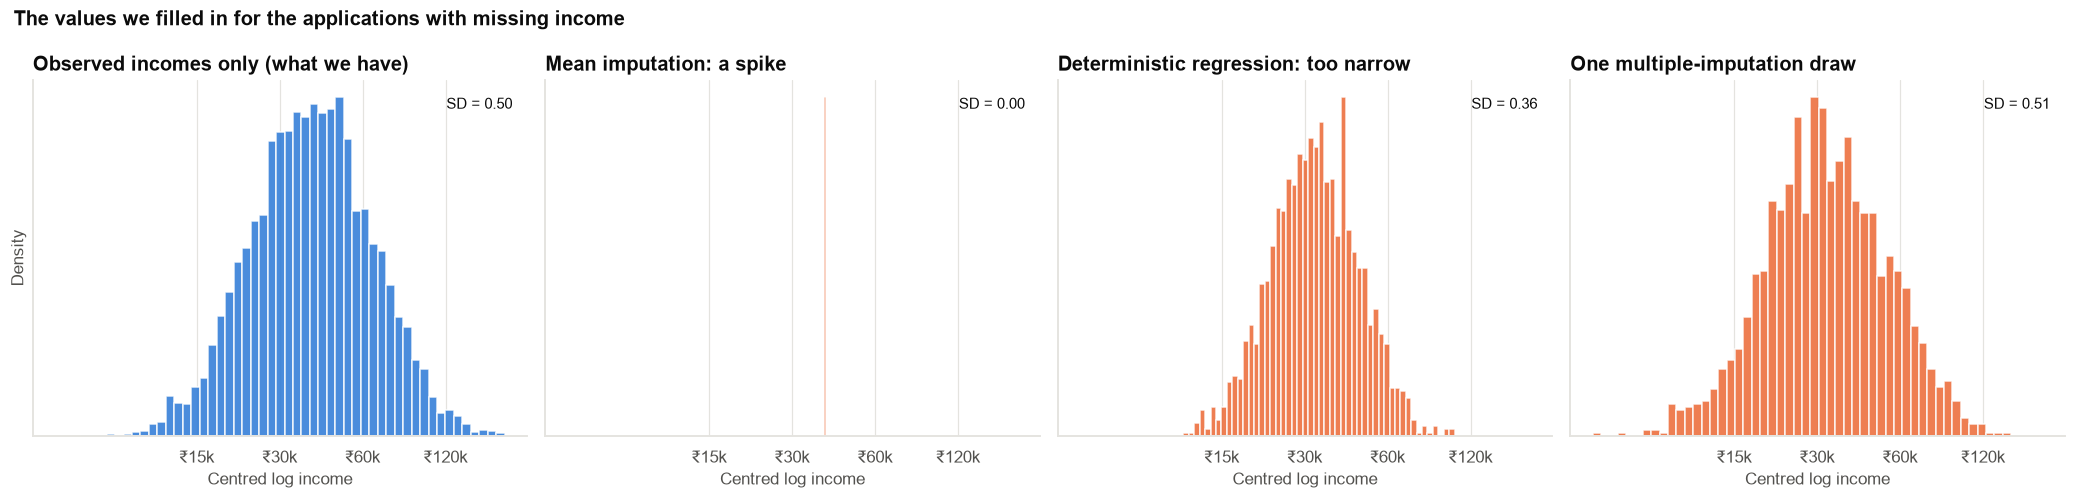

In [8]:
lis_with = imps["Multiple imputation, outcome INCLUDED"]
fig, axes = plt.subplots(1, 4, figsize=(19, 4.6), sharex=True)
panels = [("Observed incomes only (what we have)", apps.loc[obs, "li"]),
          ("Mean imputation: a spike", li_mean[~obs]),
          ("Deterministic regression: too narrow", apps["li"].fillna(pred)[~obs]),
          ("One multiple-imputation draw", lis_with[0][~obs])]
for ax, (title, v) in zip(axes, panels):
    ax.hist(v, bins=50, color=PRIMARY if "Observed" in title else HIGHLIGHT, alpha=0.85, density=True)
    ax.set(title=title, xlabel="Centred log income")
    ax.set_yticks([])
    ax.set_xticks(np.log([15_000, 30_000, 60_000, 120_000]) - LI0, ["₹15k", "₹30k", "₹60k", "₹120k"])
axes[0].set_ylabel("Density")
for ax in axes[1:]:
    ax.set_ylabel("")
for ax, v in zip(axes[1:], [li_mean[~obs], apps["li"].fillna(pred)[~obs], lis_with[0][~obs]]):
    ax.text(0.97, 0.95, f"SD = {v.std():.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=10)
axes[0].text(0.97, 0.95, f"SD = {apps.loc[obs, 'li'].std():.2f}", transform=axes[0].transAxes, ha="right", va="top", fontsize=10)
fig.suptitle("The values we filled in for the applications with missing income", x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig03_imputed_distributions", PATHS["figures"])
plt.show()

**Observation.** Mean imputation puts every missing income at one value (a spike with zero spread). Deterministic
regression imputation produces values with a narrower spread than real incomes. A multiple-imputation draw has a
realistic spread.

**Interpretation.** Filling with a single "best guess" removes the natural variation in income, which **weakens every
relationship that involves income** (the coefficient shrinks towards zero) and **overstates our certainty**. Good
imputation must put the noise **back**.

## Section 10 — Sensitivity to MNAR: what if low earners are the ones who hide income?

MI assumes that, **given the observed variables**, applicants with missing income resemble those who provided it
(MAR). If low earners are less likely to supply proof of income (MNAR), the true missing incomes are **lower** than
MI imputes. We cannot estimate by how much, but we can ask: **how far would conclusions move for a range of
plausible gaps?** The **delta adjustment** subtracts δ (in log points) from every imputed income before analysing:
δ = 0 is MAR; δ = 0.2 means the missing incomes are about 18% lower than MAR imputation suggests.

,missing incomes lower by,mean log income,"mean income (geometric, ₹)",coefficient of log income,ci_low,ci_high
δ (log points),,,,,,
0.0000,0%,-0.1736,"37,288.0203",-0.9857,-1.1313,-0.8402
0.1000,10%,-0.1970,"36,423.7889",-1.0343,-1.1773,-0.8913
0.2000,18%,-0.2205,"35,579.5880",-1.0615,-1.2006,-0.9224
0.3000,26%,-0.2439,"34,754.9533",-1.0678,-1.2019,-0.9337
0.4000,33%,-0.2674,"33,949.4313",-1.0558,-1.1841,-0.9275
0.5000,39%,-0.2908,"33,162.5790",-1.0293,-1.1514,-0.9073


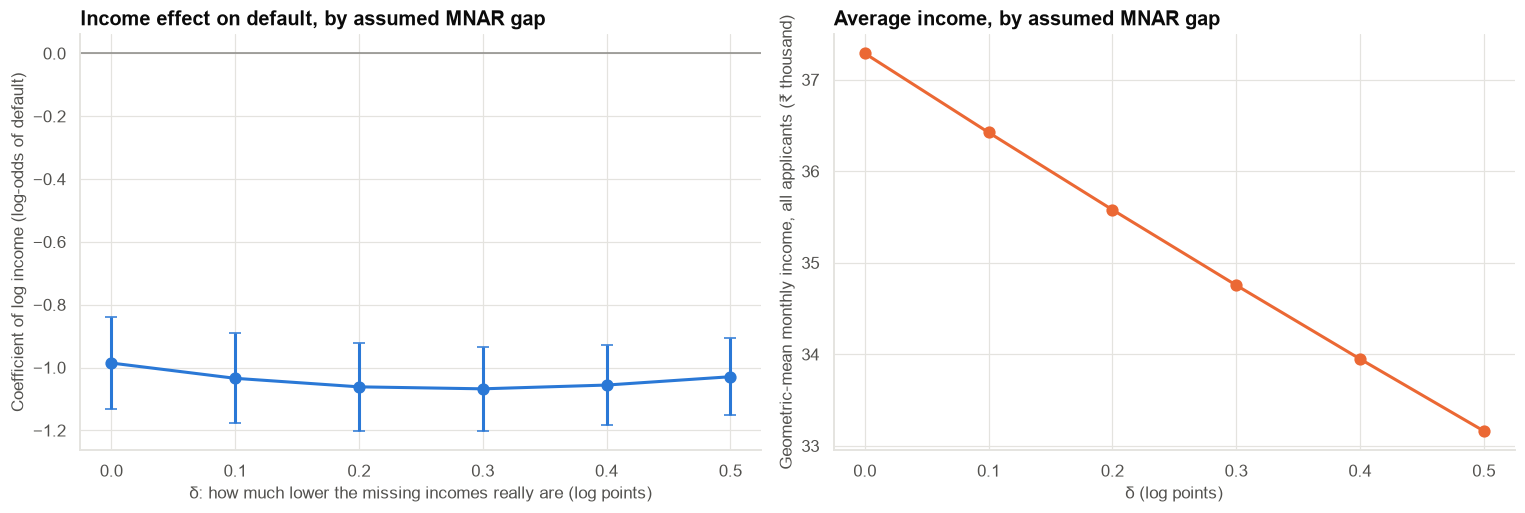

In [9]:
deltas = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5]
sens = []
for d_ in deltas:
    coefs, varis, means = [], [], []
    for li_f in lis_with[:10]:
        adj = li_f.copy(); adj[~obs] = adj[~obs] - d_
        b, se = fit_logit(apps.assign(li_f=adj), "li_f")
        coefs.append(b); varis.append(se ** 2); means.append(adj.mean())
    pc = rubin(coefs, varis)
    sens.append({"δ (log points)": d_, "missing incomes lower by": f"{100 * (1 - np.exp(-d_)):.0f}%", "mean log income": np.mean(means),
                 "mean income (geometric, ₹)": np.exp(np.mean(means) + LI0), "coefficient of log income": pc["estimate"],
                 "ci_low": pc["ci_low"], "ci_high": pc["ci_high"]})
sens = pd.DataFrame(sens).set_index("δ (log points)")
save_table(sens, "delta_sensitivity", PATHS["tables"])
display(sens)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
ax.errorbar(sens.index, sens["coefficient of log income"], yerr=[sens["coefficient of log income"] - sens["ci_low"], sens["ci_high"] - sens["coefficient of log income"]],
            fmt="o-", color=PRIMARY, capsize=4, lw=2, ms=7)
ax.axhline(0, color=INK_MUTED, lw=1)
ax.set(xlabel="δ: how much lower the missing incomes really are (log points)", ylabel="Coefficient of log income (log-odds of default)",
       title="Income effect on default, by assumed MNAR gap")
ax = axes[1]
ax.plot(sens.index, sens["mean income (geometric, ₹)"] / 1e3, "o-", color=HIGHLIGHT, lw=2, ms=7)
ax.set(xlabel="δ (log points)", ylabel="Geometric-mean monthly income, all applicants (₹ thousand)",
       title="Average income, by assumed MNAR gap")
fig.tight_layout()
save_fig(fig, "fig04_delta_sensitivity", PATHS["figures"])
plt.show()

**Observation.** As δ rises from 0 to 0.5, the estimated geometric-mean income falls from about ₹37,300 to ₹33,200
(−11%), while the income coefficient stays within about −0.99 to −1.07 (it first strengthens, then weakens), with
confidence intervals that always exclude zero. The conclusion **"higher income lowers default risk, strongly"** does
not change anywhere in the range; the **level** of average income does.

**Interpretation.** A sensitivity analysis does not tell you the truth; it tells you **which conclusions depend on the
untestable assumption and which do not**. Here the direction and rough size of the income effect are robust; the
**level** of average income is not. Report both the MI result and the range.

## Section 11 — Grading the strategies (using the answer key)

In real life nobody can do this. Because the data are simulated, we can compare each strategy with the estimate from
the **complete data** (before income was removed).

In [10]:
key = pd.read_csv(PATHS["data"] / "answer_key_teaching_only.csv")
full = apps.merge(key[["app_id", "true_income"]], on="app_id")   # (income_missing is already in apps)
full["li_true"] = np.log(full["true_income"]) - LI0
b_true, se_true = fit_logit(full, "li_true")
truth = {"mean log income": full["li_true"].mean(), "SD log income": full["li_true"].std(), "coefficient": b_true}
print(f"TRUTH (complete data): mean log income {truth['mean log income']:.3f}, SD {truth['SD log income']:.3f}, income coefficient {b_true:.3f} (SE {se_true:.3f})")
miss_true = full.loc[full["income_missing"] == 1, "li_true"]
print(f"Mean true log income of the applicants with missing income: {miss_true.mean():.3f}  vs applicants with income: {full.loc[full['income_missing'] == 0, 'li_true'].mean():.3f}")
mi_missing_mean = lis_with[0][~obs].mean()
print(f"Mean imputed log income for them (MI with outcome, one draw): {mi_missing_mean:.3f}  → the true MNAR gap δ ≈ {mi_missing_mean - miss_true.mean():.2f} log points")

grade = strategies.copy()
grade["bias in mean log income"] = grade["mean log income"] - truth["mean log income"]
grade["bias in SD"] = grade["SD log income"] - truth["SD log income"]
grade["bias in coefficient"] = grade["coefficient of log income"] - b_true
grade["coefficient bias (%)"] = 100 * grade["bias in coefficient"] / abs(b_true)
grade["CI covers the truth?"] = (grade["ci_low"] <= b_true) & (b_true <= grade["ci_high"])
save_table(grade, "strategy_grading", PATHS["tables"])
grade[["mean log income", "bias in mean log income", "SD log income", "bias in SD", "coefficient of log income", "coefficient bias (%)", "SE", "CI covers the truth?"]]

TRUTH (complete data): mean log income -0.216, SD 0.526, income coefficient -1.102 (SE 0.068)
Mean true log income of the applicants with missing income: -0.501  vs applicants with income: -0.129
Mean imputed log income for them (MI with outcome, one draw): -0.319  → the true MNAR gap δ ≈ 0.18 log points


,mean log income,bias in mean log income,SD log income,bias in SD,coefficient of log income,coefficient bias (%),SE,CI covers the truth?
strategy,,,,,,,,
Complete cases (delete missing),-0.1289,0.0873,0.5034,-0.0222,-0.9583,13.0557,0.0842,True
Mean imputation,-0.1289,0.0873,0.4404,-0.0851,-0.6552,40.5595,0.0745,False
Group-mean imputation (employment × channel),-0.1339,0.0822,0.4480,-0.0776,-0.7304,33.7399,0.0760,False
Mean + missing indicator,-0.1289,0.0873,0.4404,-0.0851,-0.8910,19.1668,0.0821,False
Regression imputation (deterministic),-0.1710,0.0451,0.4802,-0.0454,-0.8905,19.2149,0.0744,False
Stochastic regression imputation (one fill),-0.1709,0.0453,0.5097,-0.0159,-0.7359,33.2385,0.0674,False
"Multiple imputation, outcome EXCLUDED from the imputation model",-0.1714,0.0447,0.5108,-0.0148,-0.7373,33.1132,0.0775,False
"Multiple imputation, outcome INCLUDED",-0.1748,0.0413,0.5126,-0.0130,-0.9830,10.8197,0.0725,True


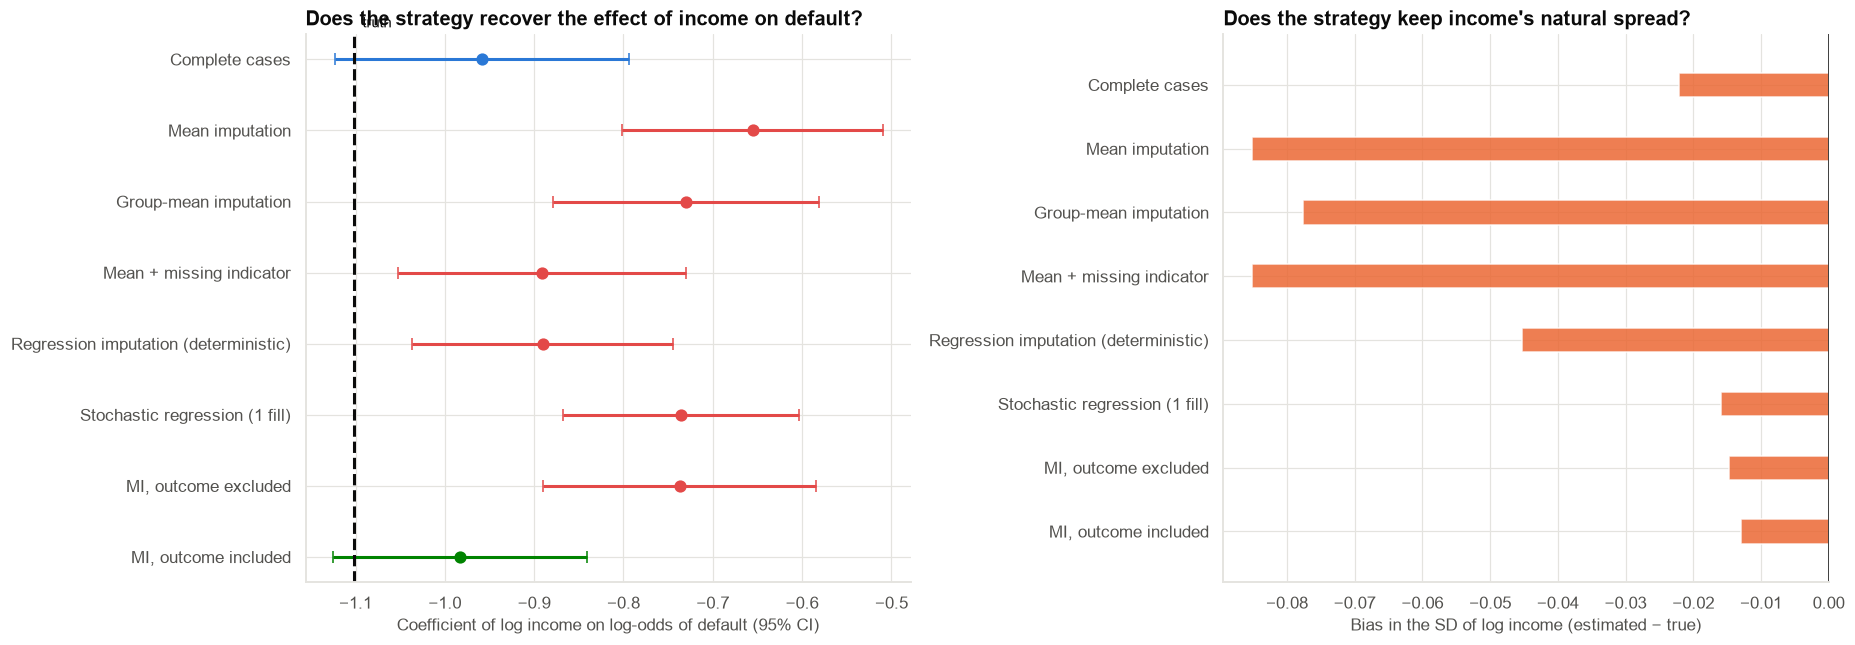

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
short = {k: k.replace("Multiple imputation, outcome EXCLUDED from the imputation model", "MI, outcome excluded")
              .replace("Multiple imputation, outcome INCLUDED", "MI, outcome included")
              .replace("Stochastic regression imputation (one fill)", "Stochastic regression (1 fill)")
              .replace("Group-mean imputation (employment × channel)", "Group-mean imputation")
              .replace("Complete cases (delete missing)", "Complete cases") for k in grade.index}
order_ = list(grade.index)[::-1]
ax = axes[0]
for i, k in enumerate(order_):
    r = grade.loc[k]
    col = COLORS["green"] if "included" in short[k].lower() else (COLORS["red"] if r["CI covers the truth?"] is False or not r["CI covers the truth?"] else PRIMARY)
    ax.errorbar(r["coefficient of log income"], i, xerr=[[r["coefficient of log income"] - r["ci_low"]], [r["ci_high"] - r["coefficient of log income"]]],
                fmt="o", color=col, capsize=4, ms=7, lw=2)
ax.axvline(b_true, color=INK, lw=2, ls="--")
ax.text(b_true + 0.01, len(order_) - 0.55, "truth", ha="left", fontsize=10)
ax.set_yticks(range(len(order_)), [short[k] for k in order_])
ax.set(xlabel="Coefficient of log income on log-odds of default (95% CI)", title="Does the strategy recover the effect of income on default?")
ax = axes[1]
for i, k in enumerate(order_):
    r = grade.loc[k]
    ax.barh(i, r["bias in SD"], color=COLORS["orange"], alpha=0.85, height=0.38)
    ax.barh(i + 0.0, 0, color="none")
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(len(order_)), [short[k] for k in order_])
ax.set(xlabel="Bias in the SD of log income (estimated − true)", title="Does the strategy keep income's natural spread?")
fig.tight_layout()
save_fig(fig, "fig05_strategy_grading", PATHS["figures"])
plt.show()

**Observation.** In this one dataset (truth: **−1.10**), the income coefficient is:

| Strategy | Estimate | Off by | 95% CI covers the truth? |
|---|---|---|---|
| Complete cases | −0.96 | 13% too weak | yes (wide: SE 0.084) |
| Mean imputation | −0.66 | 41% | **no** |
| Group-mean imputation | −0.73 | 34% | **no** |
| Mean + missing indicator | −0.89 | 19% | **no** |
| Deterministic regression imputation | −0.89 | 19% | **no** |
| Stochastic regression (one fill) | −0.74 | 33% | **no** |
| MI, outcome excluded | −0.74 | 33% | **no** |
| MI, outcome included | −0.98 | 11% | yes (SE 0.073) |

The **SD of log income** (truth 0.53) is too small after mean imputation (0.44), group-mean (0.45) and deterministic
regression (0.48); stochastic and MI methods restore it (0.51). The **mean log income** (truth −0.216) is **too high**
for every method: −0.13 for complete cases and mean imputation, −0.17 for the regression-based methods, because the
people with missing income really did earn less than imputation (which assumes MAR) can say: the true MNAR gap is
about **0.18 log points** (missing incomes about 17% lower than MAR imputation implies), within the range explored in
Section 10.

**A warning about reading one dataset.** Complete cases and MI-with-outcome both "cover the truth" here, and their
biases (13% and 11%) look similar. Whether that is luck is what Section 11.2 settles by repeating the exercise.

### 11.1 Does it matter what you put in the imputation model?
The two MI versions differ only in whether the **default outcome** was among the variables used to impute income.

In [12]:
inc_mi = {n: (pc, pm) for n, (pc, pm) in mi_detail.items()}
tbl = pd.DataFrame({n: {"pooled coefficient": pc["estimate"], "truth": b_true, "bias": pc["estimate"] - b_true,
                        "bias (%)": 100 * (pc["estimate"] - b_true) / abs(b_true),
                        "within-imputation variance": pc["within var"], "between-imputation variance": pc["between var"],
                        "fraction of missing information": pc["fraction of missing information"]}
                    for n, (pc, pm) in inc_mi.items()}).T
save_table(tbl, "mi_outcome_in_model", PATHS["tables"])
tbl

,pooled coefficient,truth,bias,bias (%),within-imputation variance,between-imputation variance,fraction of missing information
"Multiple imputation, outcome EXCLUDED from the imputation model",-0.7373,-1.1023,0.3650,33.1132,0.0045,0.0014,0.2490
"Multiple imputation, outcome INCLUDED",-0.9830,-1.1023,0.1193,10.8197,0.0047,0.0005,0.1064


**Observation.** The two MI versions differ only in whether the default outcome was among the variables used to impute
income, yet the coefficient is **−0.74** without it and **−0.98** with it (truth −1.10). The between-imputation
variance (uncertainty from the missing data) is also larger without the outcome, and the **fraction of missing
information** is 0.25 against 0.11.

**Why.** Without the outcome, the imputed incomes are drawn **as if they carried no information about default**: a
quarter of the data then show no income–default relationship, which dilutes the estimate towards zero. Including the
outcome lets the imputed values "know" which applicants defaulted, which preserves the relationship. The general rule:
**the imputation model must contain every variable used in the analysis, including the outcome, and any interactions
or non-linear terms the analysis will use.**

### 11.2 One dataset can mislead: repeat the whole exercise 150 times

A single sample can make a poor method look fine (or a good one look bad) by luck. Because the data are simulated, we
can **regenerate** the 8,000 applications 150 times, apply each strategy to every one, and compare with that dataset's
own complete-data estimate. This measures **bias** (are estimates wrong on average?) and **CI coverage** (does the
95% interval contain the right answer 95% of the time?). For speed, the two MI variants here use 5 imputations drawn
from a regression imputation model (with parameter uncertainty) rather than the iterative imputer.

In [13]:
sys.path.insert(0, str(CASE_DIR / "src"))
import generate_data as gd

def prep(df, key_):
    d = df.copy()
    d["employment_type"] = pd.Categorical(d["employment_type"], categories=["Salaried", "Self-employed", "Gig"])
    d["channel"] = pd.Categorical(d["channel"], categories=["Branch", "Online", "Agent"])
    d["li"] = np.log(d["monthly_income"]) - LI0
    d["income_missing"] = d["monthly_income"].isna().astype(int)
    d["score_missing"] = d["credit_score"].isna().astype(int)
    d["score_c"] = (d["credit_score"].fillna(650) - 700) / 10
    d["log_loan"] = np.log(d["loan_amount"])
    d["li_true"] = np.log(key_["true_income"].to_numpy()) - LI0
    return d

def coef_se(d, col):
    m = smf.logit(MODEL.format(inc=col), d).fit(disp=0)
    return m.params[col], m.bse[col]

def mi_fast(d, include_outcome, r_, m=5):
    rhs = "age + C(employment_type) + C(channel) + city_tier + log_loan + score_c + score_missing" + (" + defaulted" if include_outcome else "")
    ob = d["li"].notna()
    fit = smf.ols("li ~ " + rhs, d[ob]).fit()
    Xm = smf.ols("li ~ " + rhs, d[~ob].assign(li=0.0)).exog          # design matrix of the rows to impute (same columns)
    assert Xm.shape[1] == len(fit.params)
    cov_unscaled = fit.cov_params().to_numpy() / fit.scale
    qs, us = [], []
    for _ in range(m):
        sig2 = fit.scale * fit.df_resid / r_.chisquare(fit.df_resid)
        beta = r_.multivariate_normal(fit.params.to_numpy(), sig2 * cov_unscaled)
        li_f = d["li"].copy()
        li_f[~ob] = Xm @ beta + r_.normal(0, np.sqrt(sig2), (~ob).sum())
        q_, se_ = coef_se(d.assign(x=li_f), "x")
        qs.append(q_); us.append(se_ ** 2)
    if m == 1:
        return {"estimate": qs[0], "SE": np.sqrt(us[0])}
    return rubin(qs, us)

N_REP = 150
sim_rows = []
for rep in range(N_REP):
    r_ = np.random.default_rng(170_000 + rep)
    raw, key_ = gd.generate(r_)
    d = prep(raw, key_)
    bench, bench_se = coef_se(d.assign(x=d["li_true"]), "x")
    out = {}
    cc_ = d[d["li"].notna()]
    out["Complete cases"] = coef_se(cc_.assign(x=cc_["li"]), "x")
    mu_ = d["li"].mean()
    dm = d.assign(x=d["li"].fillna(mu_))
    out["Mean imputation"] = coef_se(dm, "x")
    mm = smf.logit("defaulted ~ x + income_missing + score_c + score_missing + C(employment_type)", dm).fit(disp=0)
    out["Mean + missing indicator"] = (mm.params["x"], mm.bse["x"])
    r1 = mi_fast(d, False, r_, m=1)
    out["Stochastic fill, one draw (no outcome)"] = (r1["estimate"], r1["SE"])
    r2 = mi_fast(d, False, r_)
    out["MI, outcome excluded"] = (r2["estimate"], r2["SE"])
    r3 = mi_fast(d, True, r_)
    out["MI, outcome included"] = (r3["estimate"], r3["SE"])
    for k, (b_, se_) in out.items():
        sim_rows.append({"rep": rep, "strategy": k, "estimate": b_, "se": se_, "benchmark": bench})
sim = pd.DataFrame(sim_rows)
sim["error"] = sim["estimate"] - sim["benchmark"]
sim["covers"] = (sim["estimate"] - 1.96 * sim["se"] <= sim["benchmark"]) & (sim["benchmark"] <= sim["estimate"] + 1.96 * sim["se"])
sim_sum = sim.groupby("strategy").agg(**{"mean estimate": ("estimate", "mean"), "mean benchmark": ("benchmark", "mean"), "mean error": ("error", "mean"),
                                         "SD of error": ("error", "std"), "mean SE reported": ("se", "mean"), "CI coverage (nominal 95%)": ("covers", "mean")})
sim_sum["bias (% of benchmark)"] = 100 * sim_sum["mean error"] / sim_sum["mean benchmark"].abs()
sim_sum["Monte Carlo SE of bias"] = sim.groupby("strategy")["error"].std() / np.sqrt(N_REP)
sim_sum["RMSE"] = np.sqrt(sim_sum["mean error"] ** 2 + sim_sum["SD of error"] ** 2)
order_s = ["Complete cases", "Mean imputation", "Mean + missing indicator", "Stochastic fill, one draw (no outcome)", "MI, outcome excluded", "MI, outcome included"]
sim_sum = sim_sum.loc[order_s]
save_table(sim_sum, "repeated_sampling_simulation", PATHS["tables"])
sim_sum

,mean estimate,mean benchmark,mean error,SD of error,mean SE reported,CI coverage (nominal 95%),bias (% of benchmark),Monte Carlo SE of bias,RMSE
strategy,,,,,,,,,
Complete cases,-0.9469,-1.1047,0.1578,0.0520,0.0854,0.5600,14.2814,0.0042,0.1661
Mean imputation,-0.6314,-1.1047,0.4733,0.0583,0.0747,0.0000,42.8406,0.0048,0.4768
Mean + missing indicator,-0.8976,-1.1047,0.2071,0.0539,0.0832,0.2200,18.7500,0.0044,0.2140
"Stochastic fill, one draw (no outcome)",-0.7509,-1.1047,0.3538,0.0476,0.0673,0.0000,32.0285,0.0039,0.3570
"MI, outcome excluded",-0.7500,-1.1047,0.3547,0.0379,0.0756,0.0000,32.1107,0.0031,0.3567
"MI, outcome included",-1.0143,-1.1047,0.0904,0.0437,0.0794,0.9133,8.1795,0.0036,0.1004


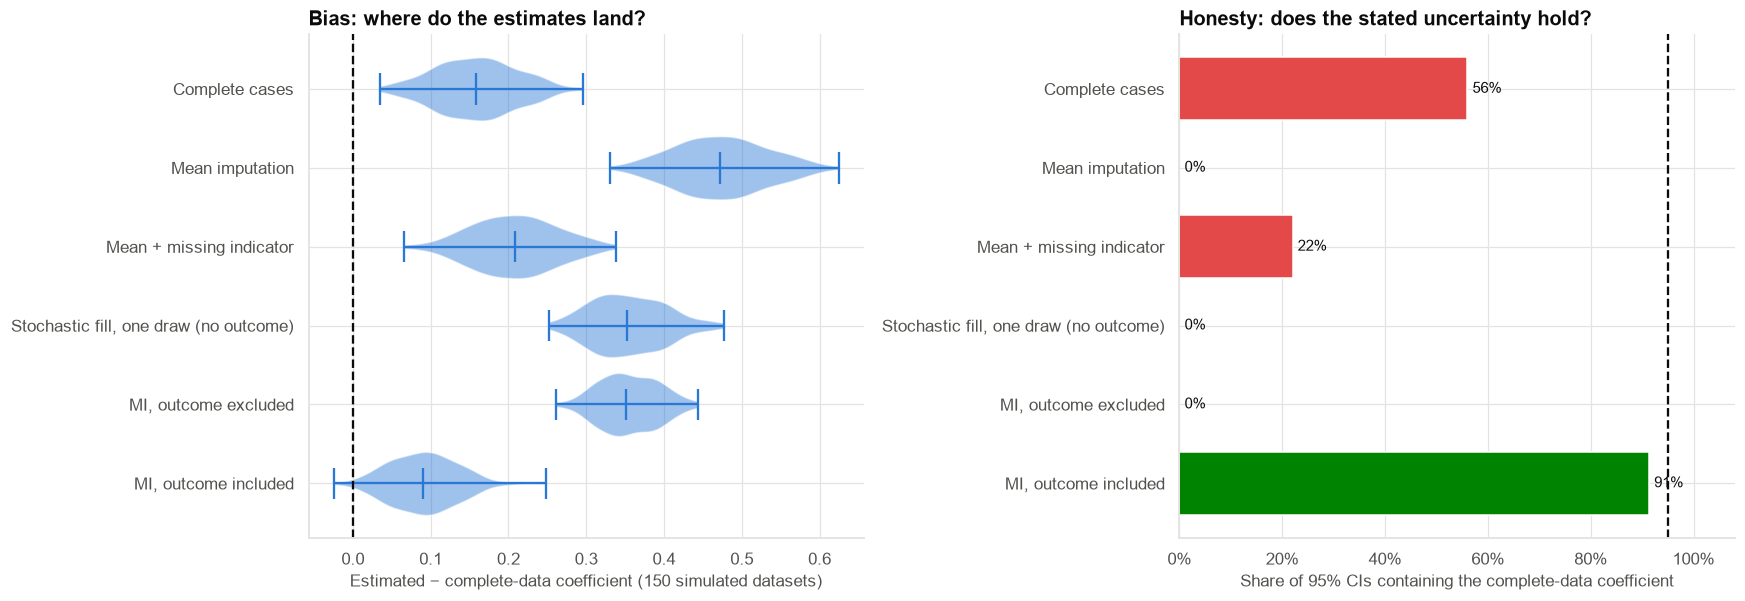

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6))
ax = axes[0]
data_ = [sim.loc[sim["strategy"] == s, "error"].to_numpy() for s in order_s][::-1]
vp = ax.violinplot(data_, orientation="horizontal", showmedians=True, widths=0.8)
for b_ in vp["bodies"]:
    b_.set_facecolor(PRIMARY); b_.set_alpha(0.45)
ax.axvline(0, color=INK, lw=1.5, ls="--")
ax.set_yticks(range(1, len(order_s) + 1), order_s[::-1])
ax.set(xlabel="Estimated − complete-data coefficient (150 simulated datasets)", title="Bias: where do the estimates land?")
ax = axes[1]
cov = sim_sum["CI coverage (nominal 95%)"][::-1]
ax.barh(range(len(cov)), cov, color=[COLORS["green"] if v >= 0.9 else COLORS["red"] for v in cov])
ax.axvline(0.95, color=INK, ls="--", lw=1.5)
for i, v in enumerate(cov):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=10)
ax.set_yticks(range(len(cov)), cov.index)
ax.xaxis.set_major_formatter(pctfmt)
ax.set(xlim=(0, 1.08), xlabel="Share of 95% CIs containing the complete-data coefficient", title="Honesty: does the stated uncertainty hold?")
fig.tight_layout()
save_fig(fig, "fig06_repeated_sampling", PATHS["figures"])
plt.show()

**Observation.** Repeating the whole exercise on 150 freshly simulated datasets (error measured against each dataset's
own complete-data estimate; Monte Carlo SE of each bias is about 0.004):

| Strategy | Bias | 95% CI coverage |
|---|---|---|
| Complete cases | **+14%** (too weak) | **56%** |
| Mean imputation | +43% | **0%** |
| Mean + missing indicator | +19% | 22% |
| Stochastic fill, one draw (no outcome) | +32% | **0%** |
| MI, outcome excluded | +32% | **0%** |
| MI, outcome included | **+8%** | **91%** |

- **Complete cases are biased**, not just noisy: the single dataset in 11 was a mild draw. The bias comes from
  missingness being related to the outcome and to income itself. Its CI covers the right answer only about half the time.
- **Single fills and MI without the outcome are not just biased, but confidently so**: their 95% CIs almost never
  contain the truth (coverage 0–22%).
- **MI with the outcome** has the smallest bias and close to nominal coverage (91%). The remaining 8% bias and slight
  under-coverage reflect the **MNAR** part of the missingness, which MI under MAR cannot remove (Section 10 is the answer
  to that).
- MI-with-outcome also has the **lowest RMSE** (0.10 against 0.17 for complete cases): it uses all the data **and**
  removes most of the bias.

## Section 12 — Estimation is not scoring: what to do for a new applicant without income?

For **inference** (what is the effect of income on default?), multiple imputation with the outcome included is the
right tool. For **scoring** a new applicant, we do **not** know the outcome yet, and the question is only "how well
can we predict?". A different set of rules applies. We train a default model on 6,000 applications and test it on 2,000
(where, as in production, income is sometimes missing):

In [15]:
train_idx, test_idx = train_test_split(apps.index, test_size=2000, random_state=17, stratify=apps["defaulted"])
tr, te = apps.loc[train_idx].copy(), apps.loc[test_idx].copy()
emp_d = lambda d: pd.get_dummies(d["employment_type"], prefix="emp", drop_first=True, dtype=float)
ch_d = lambda d: pd.get_dummies(d["channel"], prefix="ch", drop_first=True, dtype=float)

def design(d, li_col=None, flag=False):
    cols = [d[["score_c", "score_missing"]], emp_d(d)]
    if li_col is not None:
        cols.append(d[[li_col]])
    if flag:
        cols.append(d[["income_missing"]])
    return pd.concat(cols, axis=1).astype(float)

def fit_eval(Xtr, Xte, ytr=tr["defaulted"], yte=te["defaulted"]):
    clf = LogisticRegression(max_iter=3000, C=100).fit(Xtr, ytr)
    p = clf.predict_proba(Xte)[:, 1]
    return {"AUC": roc_auc_score(yte, p), "Brier score": brier_score_loss(yte, p), "log loss": log_loss(yte, p)}

pred_rows = {}
# (a) drop income entirely
pred_rows["No income variable at all"] = fit_eval(design(tr), design(te))
# (b) complete-case training, then mean-fill at scoring time
cc_tr = tr[tr["li"].notna()]
mu = cc_tr["li"].mean()
tr_f, te_f = tr.assign(li_f=tr["li"].fillna(mu)), te.assign(li_f=te["li"].fillna(mu))
clf_cc = LogisticRegression(max_iter=3000, C=100).fit(design(cc_tr.assign(li_f=cc_tr["li"]), "li_f"), cc_tr["defaulted"])
p_cc = clf_cc.predict_proba(design(te_f, "li_f"))[:, 1]
pred_rows["Train on complete cases, mean-fill at scoring"] = {"AUC": roc_auc_score(te["defaulted"], p_cc), "Brier score": brier_score_loss(te["defaulted"], p_cc), "log loss": log_loss(te["defaulted"], p_cc)}
# (c) mean imputation
pred_rows["Mean imputation (no indicator)"] = fit_eval(design(tr_f, "li_f"), design(te_f, "li_f"))
# (d) mean + missing indicator
pred_rows["Mean imputation + missing indicator"] = fit_eval(design(tr_f, "li_f", True), design(te_f, "li_f", True))
# (e) stochastic regression imputation (covariates only), applied to both
reg_tr = smf.ols("li ~ age + C(employment_type) + C(channel) + city_tier + log_loan + score_c + score_missing", cc_tr).fit()
def stoch(d, seed):
    r_ = np.random.default_rng(seed)
    out = d["li"].copy(); m_ = out.isna()
    out[m_] = reg_tr.predict(d[m_]) + r_.normal(0, np.sqrt(reg_tr.scale), m_.sum())
    return out
tr_s, te_s = tr.assign(li_f=stoch(tr, 1)), te.assign(li_f=stoch(te, 2))
pred_rows["Stochastic regression imputation + indicator"] = fit_eval(design(tr_s, "li_f", True), design(te_s, "li_f", True))
pred_tbl = pd.DataFrame(pred_rows).T
save_table(pred_tbl, "scoring_comparison", PATHS["tables"])
print(f"Test set: {len(te):,} applications, default rate {te['defaulted'].mean():.1%}, income missing for {te['income_missing'].mean():.0%}")
pred_tbl

Test set: 2,000 applications, default rate 18.8%, income missing for 24%


,AUC,Brier score,log loss
No income variable at all,0.7287,0.1355,0.4324
"Train on complete cases, mean-fill at scoring",0.7300,0.1375,0.4349
Mean imputation (no indicator),0.7366,0.1344,0.4279
Mean imputation + missing indicator,0.7666,0.1286,0.4114
Stochastic regression imputation + indicator,0.7666,0.1285,0.4118


**Observation.** On 2,000 unseen applications (24% with missing income), the ranking differs from the estimation
problem:

| Approach | Test AUC | Brier score |
|---|---|---|
| No income variable at all | 0.729 | 0.136 |
| Train on complete cases, mean-fill at scoring | 0.730 | 0.138 |
| Mean imputation (no indicator) | 0.737 | 0.134 |
| **Mean imputation + missing indicator** | **0.767** | **0.129** |
| **Stochastic imputation + indicator** | **0.767** | **0.129** |

Adding the **missing-income flag** improves the AUC by 3 points over plain mean-filling: applicants without income
default twice as often, and the flag carries that signal. Plain mean-filling barely beats ignoring income. Training
only on complete cases (the "delete them" approach) and then mean-filling at scoring time is no better than having
no income variable.

**Interpretation.** For **scoring**, the missing-indicator method is not a bias problem but a **feature**: "income not
provided" is information. (For **inference** it distorts the coefficient of the filled variable, as the simulation
showed.) The right tool depends on the question.

## Section 13 — Decision framework: what to do about missing data

| Situation | Consider | Why |
|---|---|---|
| < 5% missing and plausibly MCAR | Complete-case analysis | Little bias, little loss; check with a sensitivity run |
| Missingness depends on observed variables (MAR), **any serious amount** | **Multiple imputation**, outcome and analysis variables in the imputation model | Valid inference; honest uncertainty |
| **Outcome** related to missingness (as here) | Complete-case analysis is **biased**; use MI | Selection on the outcome |
| Missing values are structural (thin file: "no history") | Model "missing" as its own category / flag; do **not** impute a number as if it were real | The absence carries information |
| Missingness may depend on the value itself (MNAR) | MI + **delta-adjusted sensitivity analysis**; collect the data if it matters | Untestable assumption; show the range |
| **Prediction** for new cases | Mean/median fill **plus a missing indicator**, or a tree model that handles missing values | The flag carries predictive signal; no outcome available at scoring time |
| Very high missingness (> 40–50%) in a key variable | Treat the variable as unreliable; consider dropping it or fixing the collection process | Imputation cannot create information |
| Needing a one-number summary quickly | Report with and without; never silently mean-fill | Transparency |

**Things never to do**

- **Never fill with the mean and then report standard errors as if the data were complete.** Spread and uncertainty
  are understated.
- **Never leave the outcome out of the imputation model** when the analysis is about its relationship with the filled
  variable.
- **Never impute the outcome** for a supervised model's training data.
- **Never apply a "was missing" indicator in an explanatory model** and read the coefficient of the filled variable as
  a causal effect.

## Section 14 — Results

In [16]:
g = grade
summary = pd.DataFrame({"Value": [
    f"income {apps['income_missing'].mean():.1%} · credit score {apps['score_missing'].mean():.1%} (thin file) · employment years {apps['years_missing'].mean():.1%}",
    f"missingness model LR p {fmt_p(stats.chi2.sf(lr_stat, m_miss.df_model))}; AUC {roc_auc_score(apps.income_missing, m_miss.predict()):.2f}; default rate {apps.loc[apps.income_missing == 1, 'defaulted'].mean():.0%} (missing) vs {apps.loc[apps.income_missing == 0, 'defaulted'].mean():.0%} (present)",
    f"{truth['coefficient']:.3f}".replace("-", "−") + " (log-odds per unit of log income, complete data)",
    "; ".join(f"{k.split(' (')[0].replace('Multiple imputation, outcome ', 'MI ')}: {g.loc[k, 'coefficient bias (%)']:+.0f}%" for k in g.index).replace("-", "−"),
    f"true MNAR gap δ ≈ {mi_missing_mean - miss_true.mean():.2f} log points ({100 * (1 - np.exp(-(mi_missing_mean - miss_true.mean()))):.0f}% lower than MAR imputation suggests)",
    f"AUC {pred_tbl['AUC'].min():.3f}–{pred_tbl['AUC'].max():.3f}; best: {pred_tbl['AUC'].idxmax()}",
]}, index=["Missingness", "Mechanism", "Truth", "Coefficient bias by strategy", "MNAR sensitivity", "Scoring performance (test AUC)"])
save_table(summary, "results_summary", PATHS["tables"])
summary

,Value
Missingness,income 23.4% · credit score 6.2% (thin file) ·...
Mechanism,missingness model LR p < 0.001; AUC 0.72; defa...
Truth,"−1.102 (log-odds per unit of log income, compl..."
Coefficient bias by strategy,Complete cases: +13%; Mean imputation: +41%; G...
MNAR sensitivity,true MNAR gap δ ≈ 0.18 log points (17% lower t...
Scoring performance (test AUC),AUC 0.729–0.767; best: Stochastic regression i...


## Section 15 — Interpretation

- **Income is missing for a reason that matters.** It depends on employment type, channel, loan size, and the default
  outcome (and probably on income itself). A deleted-rows analysis would study a **selected** subsample.
- **Single fills (mean, regression) are not neutral.** They shrink the spread of income, weaken relationships and
  understate uncertainty.
- **Multiple imputation with the outcome in the model** comes closest to the truth (bias 8% in 150 repeated
  datasets, coverage 91%) and reports honest uncertainty. Leaving the outcome out is as bad as a single fill (bias
  32%, coverage 0%). The remaining bias reflects the MNAR part of the mechanism, which no imputation fixes.
- **Scoring is a different job.** With no outcome available, the practical, well-performing approach is a simple fill
  plus a **missing indicator**, because *not providing income is itself a risk signal*.

## Section 16 — What can we say?

| ✅ We can say | ❌ We cannot say |
|---|---|
| "Income is not missing at random: it depends on employment type, channel and default." | "The missing values are random, so deleting them is safe." |
| "After multiple imputation, a 10% higher income is associated with about X% lower odds of default (95% CI shown)." | "Missing incomes are like observed ones" (an assumption; see the sensitivity analysis). |
| "The conclusion about the direction of the income effect holds for all plausible MNAR gaps tested." | "We know how much lower the missing incomes are." (The data cannot say.) |
| "A missing-income flag improves scoring because applicants without income default more." | "Not providing income causes default." |

## Section 17 — Business interpretation

- **Scorecard development:** use multiple imputation (outcome included) for coefficient estimation and reporting; do
  not delete applications without income.
- **Scoring in production:** keep a **missing-income flag**; its effect on risk should be reviewed, because it can
  encode channel and agent behaviour.
- **Process:** the strongest predictor of missing income is channel (agent) and employment type: fix the collection
  process at the source, since no model can restore what is never collected.

## Section 18 — Limitations

- The simulated mechanism is simple. Real missingness has many causes; imputation models should be checked with
  diagnostics (compare observed and imputed distributions).
- Only one variable was imputed for the analysis; real projects impute several at once.
- MNAR cannot be tested; δ-adjustment is a what-if, not a correction.
- Synthetic data.

## Section 19 — Final recommendation

> **Do not delete applications with missing income and do not fill with the mean.** For the scorecard's coefficients,
> use **multiple imputation with the default outcome in the imputation model** (m ≥ 20, Rubin's rules) and report the
> **delta-sensitivity range**. For **scoring** in production, use **mean-fill plus a missing-income flag**. Treat the
> missing-income rate by channel as a **data-quality KPI**.

## Section 20 — What would I do next?

1. **Audit a sample**: chase income documents for a random sample of applications with missing income, to measure the
   true MNAR gap and replace the sensitivity analysis with data.
2. Impute **several variables jointly** (income, employment years) with `mice`-style chained equations and check
   imputed vs observed distributions.
3. Compare with a **gradient-boosting scorecard** that handles missing values natively (Case 13's playbook).
4. Monitor the **missing-income rate by channel** monthly; sudden changes signal process or fraud issues.
5. Continue to **Case 18** (survey sampling, bias and weighting).